In [ ]:
import os
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [ ]:
name = os.path.basename(os.getcwd())
pth = os.path.join('..', '..', '..', '..', '..', '..')
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Head-and-Neck', name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Head-and-Neck', name)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad'))
adata

In [ ]:
# The EMT-TF readout is scored gated on DETECTABLE expression and spans mesenchymal
# TF families beyond Snail/Zeb/Twist -- FOXC and PRRX -- per the Kurten rule.
# VIM is deliberately EXCLUDED: vimentin is a mesenchymal marker, not a TF.
candidates = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2',
              'FOXC1','FOXC2','PRRX1','PRRX2']
candidates = [g for g in candidates if g in adata.var_names]
X = adata[:, candidates].to_df()
tab = pd.DataFrame({'pct_expr': (X > 0).mean() * 100, 'p99': X.quantile(0.99)}).round(2)
tab = tab.sort_values('pct_expr', ascending = False)
print(tab.to_string())
# 'Detectable' = expressed in >=10% of malignant cells. The canonical
# Snail/Zeb/Twist factors are largely below detection here; the detectable
# mesenchymal TFs are what the readout shows.
detectable = tab.index[tab.pct_expr >= 10].tolist()
print('\ndetectable (>=10% cells):', detectable)
print('below detection:', [g for g in candidates if g not in detectable])

        pct_expr   p99
genes                 
PRRX1      62.28  1.25
SNAI2      24.44  0.84
FOXC1      13.26  0.55
ZEB2       12.96  0.49
ZEB1        7.35  0.30
TWIST2      5.93  0.38
FOXC2       4.27  0.37
PRRX2       2.31  0.21
SNAI1       1.55  0.08
TWIST1      0.95  0.00

detectable (>=10% cells): ['PRRX1', 'SNAI2', 'FOXC1', 'ZEB2']
below detection: ['SNAI1', 'ZEB1', 'TWIST1', 'TWIST2', 'FOXC2', 'PRRX2']


In [ ]:
# Two-factor overlay (reference layout): a root-end FOXC-family factor and a
# terminus Snail-family factor -- the FOXC1 -> SNAI2 axis reported for the
# Kurten non-branching case. Confirm both are detectable before showing them.
g_plt = {}
if 'FOXC1' in detectable: g_plt['FOXC1'] = 'tab:blue'
if 'SNAI2' in detectable: g_plt['SNAI2'] = 'tab:red'
# broadest-expressed mesenchymal TF as context, if detectable
if 'PRRX1' in detectable: g_plt['PRRX1'] = 'tab:green'
# per-gene display threshold = 90th percentile of that gene (data-driven; avoids
# an outlier-dominated scale -- attempt-3 'display cutoff unset' failure)
thr = {g: float(np.quantile(X[g], 0.90)) for g in g_plt}
print('overlay genes + thresholds:', {g: round(t, 3) for g, t in thr.items()})

overlay genes + thresholds: {'FOXC1': 0.086, 'SNAI2': 0.287, 'PRRX1': 0.835}


saved expression.pdf -> ../../../../../../figures/cancer/vertebrate/CCCA/Claude/Head-and-Neck/Chen2020_Head-and-Neck-4


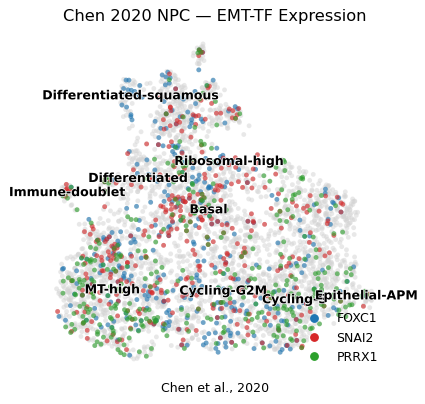

In [ ]:
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, size = 60, alpha = .5, frameon = False, show = False, ax = ax)
for var, c in g_plt.items():
    sub = adata[adata[:, var].X.toarray().ravel() > thr[var]].copy()
    sc.pl.umap(sub, na_color = c, size = 60, alpha = .6, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'subtype', size = 60, alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False, show = False, ax = ax)
from matplotlib.lines import Line2D
ax.legend(handles = [Line2D([0],[0], marker='o', ls='', color=c, label=g) for g,c in g_plt.items()],
          loc = 'lower right', frameon = False)
ax.set_title('Chen 2020 NPC — EMT-TF Expression', size = 13)
ax.text(.5, -.05, 'Chen et al., 2020', ha = 'center', transform = ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches = 'tight')
print('saved expression.pdf ->', pth_fig)

In [ ]:
# Directionality: does the root-end factor precede the terminus factor along the
# developmental axis? Read pseudotime t from signatures.h5ad (curve trajectory).
sig = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad'))
t = sig.obs['t']
for g in g_plt:
    r = np.corrcoef(t, X[g])[0,1]
    print(f'corr(t, {g}) = {r:+.3f}   (t<0 root-end / Gast-pSom-high; t>0 terminus / Crest-high)')

corr(t, FOXC1) = -0.062   (t<0 root-end / Gast-pSom-high; t>0 terminus / Crest-high)
corr(t, SNAI2) = -0.027   (t<0 root-end / Gast-pSom-high; t>0 terminus / Crest-high)
corr(t, PRRX1) = +0.129   (t<0 root-end / Gast-pSom-high; t>0 terminus / Crest-high)
